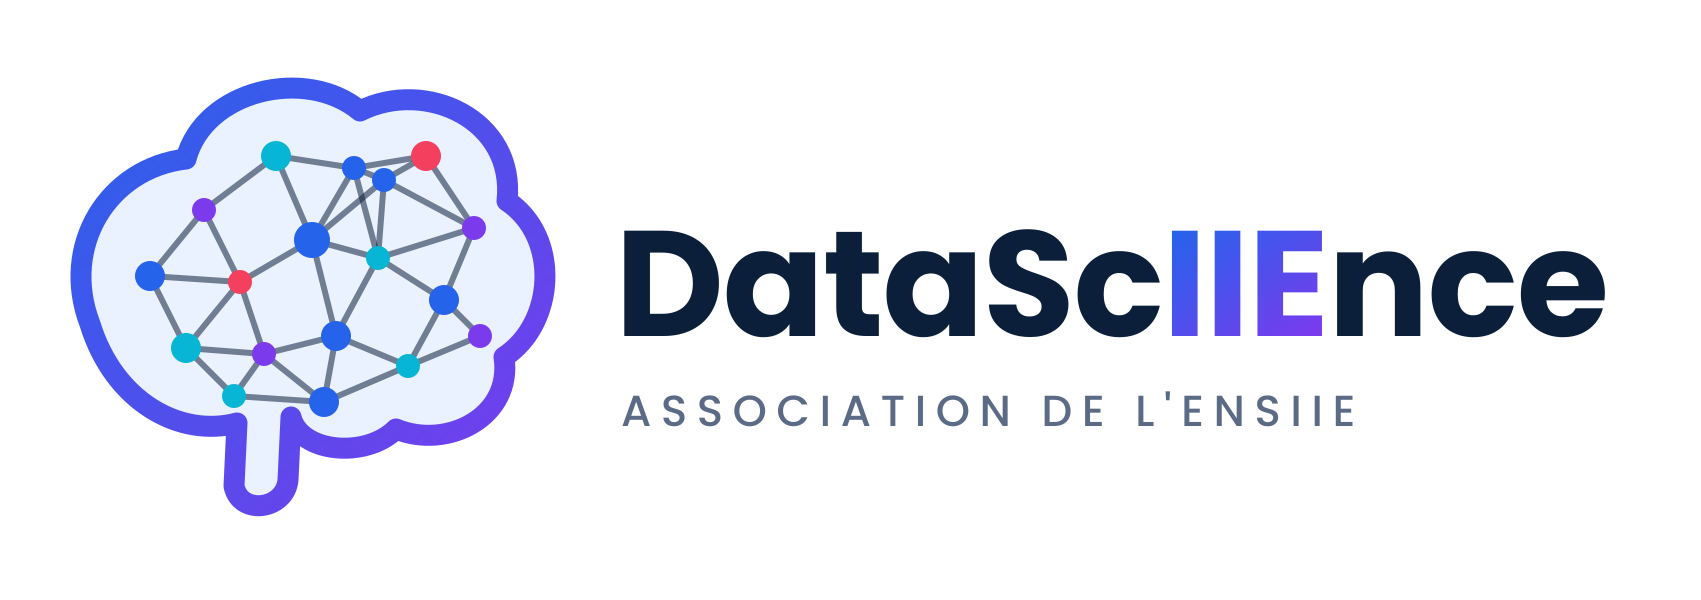

# A quoi sert le web scraping?
Source: https://www.data-bird.co/blog/web-scraping
***
- **Le suivi des prix**: Les entreprises, de l'aviation au e-commerce, utilisent le scraping pour observer les changements de prix en temps réel et ajuster leurs propres tarifs en conséquence.

- **La veille concurrentielle**: Il permet d'analyser les stratégies des concurrents en collectant des données accessibles publiquement sur leurs sites web.

- **La génération de leads**:  Les entreprises peuvent recueillir des informations de contact pertinentes à partir de divers sites pour des campagnes de marketing ciblées.

- **L'analyse sentimentale**: Analyser les opinions et sentiments exprimés sur les réseaux sociaux et forums pour comprendre l'attitude des consommateurs vis-à-vis de produits ou services.

# Objectif

Dans cette formation, **nous allons explorer deux méthodes de web scraping** :

1.   **Requests et BeautifulSoup** : pour extraire des données statiques à partir d'une page HTML.
2.   **Playwright** : une approche plus avancée pour manipuler des sites web dynamiques en automatisant un navigateur.

Nous commencerons par scraper une page HTML simple avec **BeautifulSoup**, une méthode rapide et efficace lorsque le contenu d'un site est entièrement présent dans le HTML renvoyé par le serveur. Ensuite, nous verrons **pourquoi cette méthode échoue sur un site dynamique**, et nous utiliserons **Playwright** pour simuler les actions d'un humain (attendre le chargement du JavaScript, cliquer sur « page suivante »...).

**Sites utilisés dans cette formation** : `books.toscrape.com` et `quotes.toscrape.com`. Ce sont des **sites d'entraînement créés exactement pour apprendre le scraping** : on peut les scraper sans risque juridique. Ce n'est pas le cas de la plupart des sites réels (voir la section éthique en fin de notebook).

## Avant de lancer le notebook sur Google Colab

*   **Exécutez les cellules dans l'ordre**, de haut en bas.
*   Dans la partie Playwright, on utilise `await` directement dans les cellules : c'est normal dans Colab/Jupyter (une boucle `asyncio` tourne déjà). **N'utilisez pas `asyncio.run()`** dans un notebook, cela provoque une erreur.
*   Gardez **`headless=True`** : Colab n'a pas d'écran, `headless=False` fait planter le lancement du navigateur.
*   Si vous obtenez *"Executable doesn't exist"* ou *"Host system is missing dependencies"* : relancez la cellule d'installation de Playwright, puis **Exécution > Redémarrer la session** et relancez le notebook.

# **Requests et BeautifulSoup**

**Le scraping de site web avec Requests et BeautifulSoup** consiste à télécharger une page HTML (avec Requests) et à extraire des informations à l'aide de BeautifulSoup. Cette approche fonctionne bien pour les sites statiques où les données se trouvent directement dans le HTML renvoyé par le serveur.

**Utilisation adaptée :**

*   **Sites statiques :** Les pages ne nécessitent pas d'interactions utilisateur pour charger les données (ex. scroll, clics).
*   **Avantages :** Léger, rapide à mettre en place.
*   **Limites :** Ne fonctionne pas pour les sites dynamiques où les données sont chargées via JavaScript.

## Importation des bibliothèques

**pandas** pour la manipulation des données, **BeautifulSoup** pour le parsing HTML, **requests** pour les requêtes HTTP, et **re** pour les expressions régulières (pas spécifique au scraping, mais très utile pour nettoyer les données).

In [3]:
import re
import pandas as pd
import requests
from bs4 import BeautifulSoup

## Récupération du fichier HTML

**Ce premier site est un site d'entraînement, il est scrappable.**

In [4]:
url = "https://books.toscrape.com/catalogue/category/books/philosophy_7/index.html"

# timeout : évite qu'une cellule reste bloquée indéfiniment si le serveur ne répond pas
response = requests.get(url, timeout=10)

# Ce site ne précise pas son encodage : sans cette ligne, requests devine "ISO-8859-1"
# et le symbole £ s'affiche "Â£". On force l'UTF-8.
response.encoding = "utf-8"

print(response.status_code)
type(response)

200


requests.models.Response

On envoie une requête GET pour récupérer la page HTML du site. Le statut de la réponse est affiché (**200 signifie que la page a été récupérée avec succès**).

**Exemple d'un site qui bloque les requêtes automatiques**

In [5]:
url_amazon = "https://www.amazon.com"

# On encadre par un try/except : selon la machine, la requête peut être bloquée ou rester sans réponse
try:
    response_amazon = requests.get(url_amazon, timeout=10)
    print(response_amazon.status_code)
except requests.exceptions.RequestException as e:
    print("Requête bloquée / échouée :", e)

503


Ici, la requête vers Amazon est très souvent refusée (code d'erreur, captcha...) car **Amazon utilise des techniques anti-scraping**. Les méthodes simples comme Requests ne fonctionnent pas. Il existe des moyens de contourner ces protections, mais **contourner une protection technique est souvent contraire aux conditions d'utilisation du site, voire illégal** : **n'insistez pas** quand un site vous bloque.

Nous vous conseillons vivement de **vous renseigner sur la législation concernant la pratique du Web-Scraping** avant de scraper un site réel.

## Parsing du HTML avec BeautifulSoup

In [6]:
# On précise le parser "html.parser" (sinon BeautifulSoup affiche un avertissement)
soup = BeautifulSoup(response.text, "html.parser")
soup


<!DOCTYPE html>

<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html class="no-js" lang="en-us"> <!--<![endif]-->
<head>
<title>
    Philosophy | 
     Books to Scrape - Sandbox

</title>
<meta content="text/html; charset=utf-8" http-equiv="content-type"/>
<meta content="24th Jun 2016 09:29" name="created"/>
<meta content="
    
" name="description"/>
<meta content="width=device-width" name="viewport"/>
<meta content="NOARCHIVE,NOCACHE" name="robots"/>
<!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
<!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->
<link href="../../../../static/oscar/favicon.ico" rel="shortcut icon"/>
<link href="../../../../static/oscar/css/styles.css" rel="stylesh

On utilise BeautifulSoup pour parser la page HTML téléchargée et permettre d'extraire les informations structurées sous forme d'objets Python.

## Extraction des données

On observe (clic droit > *Inspecter* dans le navigateur) que toutes les infos que l'on souhaite récupérer sont dans les balises `<article>`.

In [7]:
articles = soup.find_all("article")
print(len(articles), "livres trouvés")
articles[0]

11 livres trouvés


<article class="product_pod">
<div class="image_container">
<a href="../../../sophies-world_966/index.html"><img alt="Sophie's World" class="thumbnail" src="../../../../media/cache/65/71/6571919836ec51ed54f0050c31d8a0cd.jpg"/></a>
</div>
<p class="star-rating Five">
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
</p>
<h3><a href="../../../sophies-world_966/index.html" title="Sophie's World">Sophie's World</a></h3>
<div class="product_price">
<p class="price_color">£15.94</p>
<p class="instock availability">
<i class="icon-ok"></i>
    
        In stock
    
</p>
<form>
<button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">Add to basket</button>
</form>
</div>
</article>

On cherche toutes les balises `<article>`, qui contiennent les informations sur les livres. Le premier article est affiché pour inspection.

In [8]:
titre = []       # titre du livre
prix = []        # prix du livre
bool_stock = []  # livre en stock ou pas

for article in articles:
    # titre : balise <a> à l'intérieur de <h3>, attribut "title"
    a_tag = article.find("h3").find("a")
    titre.append(a_tag.get_text()) # ou a_tag['Title']

    # prix et disponibilité : dans le bloc de classe "product_price"
    div_price = article.find(class_="product_price")
    prix.append(div_price.find(class_="price_color").get_text())
    bool_stock.append(div_price.find(class_="instock availability").get_text().strip())

Ce bloc de code parcourt chaque article pour extraire :

*   Le titre du livre (attribut `title` de la balise `a`, dans `h3`).
*   Le prix (balise de classe `price_color`).
*   La disponibilité en stock (balise de classe `instock availability`).

## Création d'un DataFrame pandas

In [9]:
df = pd.DataFrame({"Titre": titre, "Prix": prix, "Stock": bool_stock})
df

,Titre,Prix,Stock
0,Sophie's World,£15.94,In stock
1,The Death of Humanity: ...,£58.11,In stock
2,The Stranger,£17.44,In stock
3,Proofs of God: Classical ...,£54.21,In stock
4,Kierkegaard: A Christian Missionary ...,£47.13,In stock
5,At The Existentialist Café: ...,£29.93,In stock
6,Critique of Pure Reason,£20.75,In stock
7,"Run, Spot, Run: The ...",£20.02,In stock
8,The Nicomachean Ethics,£36.34,In stock
9,Meditations,£25.89,In stock


On stocke les données extraites dans un tableau pandas avec **trois colonnes : Titre, Prix, et Stock.**

## Nettoyage des données

In [10]:
def returns_only_number(price):
    price = re.findall(r"\d+\.\d+", price) # return une liste de textes du type "chiffres.chiffres".
    return float(price[0]) if price else None

df["Prix"] = df["Prix"].apply(returns_only_number)
df

,Titre,Prix,Stock
0,Sophie's World,15.94,In stock
1,The Death of Humanity: ...,58.11,In stock
2,The Stranger,17.44,In stock
3,Proofs of God: Classical ...,54.21,In stock
4,Kierkegaard: A Christian Missionary ...,47.13,In stock
5,At The Existentialist Café: ...,29.93,In stock
6,Critique of Pure Reason,20.75,In stock
7,"Run, Spot, Run: The ...",20.02,In stock
8,The Nicomachean Ethics,36.34,In stock
9,Meditations,25.89,In stock


Cette fonction utilise une expression régulière pour extraire uniquement le nombre des valeurs de prix (par exemple, **"£51.77" devient 51.77**). La colonne **Prix ne contient plus que des valeurs numériques**, ce qui permet de calculer des moyennes, de trier, etc.

In [11]:
print("Prix moyen :", round(df["Prix"].mean(), 2))
df.sort_values("Prix", ascending=False).head(3)

Prix moyen : 33.56


,Titre,Prix,Stock
1,The Death of Humanity: ...,58.11,In stock
3,Proofs of God: Classical ...,54.21,In stock
4,Kierkegaard: A Christian Missionary ...,47.13,In stock


# **Playwright** (Scraping dynamique)

Playwright permet d'**interagir avec les sites dynamiques en simulant des actions comme des clics et du défilement à partir d'un vrai navigateur**. On l'utilise quand les données sont chargées par **JavaScript** après l'affichage de la page.

**Utilisation adaptée :**

*   **Sites dynamiques :** Les pages nécessitent des interactions utilisateur (scroll, clics) ou chargent des données après l'affichage initial.
*   **Avantages :** Permet d'interagir avec des sites complexes.
*   **Limites :** Plus lent et plus complexe que BeautifulSoup.

## Pourquoi Requests + BeautifulSoup ne suffit plus ?

`quotes.toscrape.com` existe en deux versions : une page **statique** (`/`) et une page **dynamique** (`/js/`) dont les citations sont ajoutées par JavaScript. Comparons ce que "voit" BeautifulSoup dans les deux cas.

In [12]:
for page_url in ["https://quotes.toscrape.com/", "https://quotes.toscrape.com/js/"]:
    r = requests.get(page_url, timeout=10)
    s = BeautifulSoup(r.text, "html.parser")
    print(f"{page_url} -> {len(s.find_all('div', class_='quote'))} citations trouvées")

https://quotes.toscrape.com/ -> 10 citations trouvées
https://quotes.toscrape.com/js/ -> 0 citations trouvées


La version statique renvoie 10 citations, la version dynamique **0** : le HTML reçu par `requests` ne contient pas encore les citations, elles sont créées ensuite par le JavaScript du navigateur. Il nous faut donc **un vrai navigateur**, c'est le rôle de Playwright.

## Installation de Playwright et lancement du navigateur

Installation de la bibliothèque Playwright et du navigateur Chromium.

⚠️ Sur Colab, **`--with-deps` est indispensable** : il installe aussi les librairies système dont Chromium a besoin.

In [13]:
!pip install -q playwright
!playwright install --with-deps chromium

import asyncio
import pandas as pd
from playwright.async_api import async_playwright

Installing dependencies...
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [79.0 kB]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.6 MB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,471 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/multiverse amd6

## Constantes et fonction de navigation avec tentatives répétées

On regroupe les URL et sélecteurs CSS au même endroit. La fonction `goto_with_retry` retente la navigation (3 essais) en cas de lenteur ou d'erreur réseau.

In [14]:
BASE_URL = "https://quotes.toscrape.com"
START_URL = BASE_URL + "/js/"

QUOTE_SELECTOR = "div.quote"
TEXT_SELECTOR = "span.text"
AUTHOR_SELECTOR = "small.author"
TAG_SELECTOR = "a.tag"
NEXT_SELECTOR = "li.next > a"

DELAY_BETWEEN_PAGES = 1   # secondes : on évite de surcharger le serveur


async def goto_with_retry(page, url, retries=3):
    for attempt in range(1, retries + 1):
        try:
            await page.goto(url, timeout=30000)
            return
        except Exception as e:
            print(f"Tentative {attempt}/{retries} échouée : {e}")
            if attempt == retries:
                raise
            await asyncio.sleep(2 * attempt)

## Fonction pour extraire les citations d'une page

On **attend d'abord que les citations apparaissent** (`wait_for_selector`) : c'est ce qui permet de laisser le JavaScript s'exécuter. Ensuite, on parcourt chaque citation avec des *locators* pour récupérer le texte, l'auteur et les tags.

In [15]:
async def scrape_page(page):
    # Attend que le JavaScript ait créé les citations (max 30 s par défaut)
    await page.wait_for_selector(QUOTE_SELECTOR)

    quotes = page.locator(QUOTE_SELECTOR)
    rows = []
    for i in range(await quotes.count()):
        q = quotes.nth(i)
        tags = await q.locator(TAG_SELECTOR).all_inner_texts()
        rows.append({
            "citation": await q.locator(TEXT_SELECTOR).inner_text(),
            "auteur": await q.locator(AUTHOR_SELECTOR).inner_text(),
            "tags": ", ".join(tags),
        })
    return rows

## Boucle de collecte : naviguer de page en page

La fonction `run` ouvre le navigateur, scrape la page courante, **clique sur le bouton "Next"** tant qu'il existe (dans la limite de `max_pages`), puis renvoie un DataFrame pandas. Le clic sur un bouton est typiquement ce que `requests` ne sait pas faire.

In [16]:
async def run(max_pages=3):
    all_rows = []

    async with async_playwright() as p:
        # headless=True obligatoire sur Colab (pas d'écran)
        browser = await p.chromium.launch(headless=True)
        page = await browser.new_page()

        await goto_with_retry(page, START_URL)

        for n in range(1, max_pages + 1):
            rows = await scrape_page(page)
            all_rows.extend(rows)
            print(f"Page {n} : {len(rows)} citations récupérées")

            # Y a-t-il un bouton "Next" ?
            next_button = page.locator(NEXT_SELECTOR)
            if n == max_pages or await next_button.count() == 0:
                break

            await next_button.click()
            await page.wait_for_url(f"**/page/{n + 1}/")   # attend le changement de page
            await asyncio.sleep(DELAY_BETWEEN_PAGES)

        await browser.close()

    return pd.DataFrame(all_rows)

## Lancement du scraping

Dans Colab/Jupyter, on appelle directement `await run(...)`. (Dans un script `.py` classique, on écrirait `asyncio.run(run(...))`.)

In [17]:
df_quotes = await run(max_pages=3)
df_quotes

Page 1 : 10 citations récupérées
Page 2 : 10 citations récupérées
Page 3 : 10 citations récupérées


,citation,auteur,tags
0,“The world as we have created it is a process ...,Albert Einstein,"change, deep-thoughts, thinking, world"
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,"abilities, choices"
2,“There are only two ways to live your life. On...,Albert Einstein,"inspirational, life, live, miracle, miracles"
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,"aliteracy, books, classic, humor"
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,"be-yourself, inspirational"
5,“Try not to become a man of success. Rather be...,Albert Einstein,"adulthood, success, value"
6,“It is better to be hated for what you are tha...,André Gide,"life, love"
7,"“I have not failed. I've just found 10,000 way...",Thomas A. Edison,"edison, failure, inspirational, paraphrased"
8,“A woman is like a tea bag; you never know how...,Eleanor Roosevelt,misattributed-eleanor-roosevelt
9,"“A day without sunshine is like, you know, nig...",Steve Martin,"humor, obvious, simile"


## Nettoyage et export

In [18]:
# Les citations sont entourées de guillemets typographiques “ ” : on les retire
df_quotes["citation"] = df_quotes["citation"].str.strip("“”")

# Quels sont les auteurs les plus cités ?
df_quotes["auteur"].value_counts().head(5)

,count
auteur,
Albert Einstein,6
J.K. Rowling,3
Marilyn Monroe,2
Dr. Seuss,2
Bob Marley,2


In [19]:
df_quotes.to_csv("citations.csv", index=False, encoding="utf-8")

# Pour télécharger le fichier depuis Colab :
# from google.colab import files
# files.download("citations.csv")

Le résultat final est un DataFrame pandas (citation, auteur, tags) exploitable pour des analyses ou des traitements ultérieurs, ou exportable en CSV.

## Comparaison avec Selenium

**Selenium est un autre outil très populaire** pour piloter un navigateur. Il existe depuis plus longtemps, dispose d'une très grande communauté et d'une documentation abondante.

Playwright est plus récent : il **attend automatiquement** que les éléments soient prêts avant d'agir (moins de `sleep()` à écrire), gère plusieurs navigateurs et plusieurs langages, et propose de bons outils de débogage (génération de code avec `playwright codegen`, *trace viewer*, captures d'écran). Les deux outils permettent de faire des tâches similaires.

## Importance d'un scraping éthique et légal

Le scraping doit toujours respecter les règles du site visé. Avant de scraper un site réel :

*   **Lisez ses conditions d'utilisation (CGU).** Beaucoup de sites interdisent explicitement les robots et le scraping. C'est le cas de grandes plateformes comme **Amazon ou Airbnb** : nous ne les utilisons donc pas comme terrain d'entraînement.
*   **Consultez le fichier `robots.txt`** (ex. `https://site.com/robots.txt`) qui indique les parties du site que les robots ne doivent pas visiter.
*   **Limitez la fréquence des requêtes** pour ne pas surcharger le serveur (pauses entre les pages).
*   **Ne contournez jamais une protection** (captcha, blocage d'IP, faux user-agent...) : si le site vous bloque, arrêtez.
*   **Ne collectez pas de données personnelles** sans base légale (RGPD), et ne republiez pas des données protégées.
*   **Privilégiez l'API officielle** du site quand elle existe, ou les jeux de données ouverts.

Un scraping éthique préserve les ressources du site et évite les risques juridiques. *(Ce notebook est un support pédagogique, pas un avis juridique.)*

In [20]:
# Vérifier si un robot a le droit de visiter une page selon le robots.txt
from urllib.robotparser import RobotFileParser

rp = RobotFileParser("https://quotes.toscrape.com/robots.txt")
rp.read()
print(rp.can_fetch("*", "https://quotes.toscrape.com/js/"))   # True = autorisé

True


## À vous de jouer

1.   **BeautifulSoup** : scrapez les **50 pages** du catalogue complet de `books.toscrape.com` (URL de la forme `https://books.toscrape.com/catalogue/page-1.html`, `page-2.html`...) avec une boucle, en laissant une pause d'une seconde entre chaque page. Calculez ensuite le prix moyen de tous les livres.
2.   **Éthique** : choisissez un site de votre choix, trouvez son `robots.txt` et ses CGU, et dites si vous auriez le droit de le scraper. Justifiez.

In [21]:
#1
import time
from bs4 import BeautifulSoup
import requests
import pandas as pd

titre = []
prix = []
bool_stock = []

for i in range(1, 51):
  url="https://books.toscrape.com/catalogue/page-"+str(i)+".html"
  response = requests.get(url, timeout=10)
  response.encoding = "utf-8"

  soup_i = BeautifulSoup(response.text, "html.parser")

  articles = soup_i.find_all("article")
  for article in articles:
    a_tag = article.find("h3").find("a")
    titre.append(a_tag.get_text())

    div_price = article.find(class_="product_price")
    prix.append(div_price.find(class_="price_color").get_text())
    bool_stock.append(div_price.find(class_="instock availability").get_text().strip())

  # Pause d'une seconde entre chaque page (sauf après la dernière) en pratique.
  # Dans ce cas précis, 0.1 seconde suffit (site de test du scraping)
  if i < 50:
    time.sleep(0.1)

book_data = pd.DataFrame({"Titre": titre, "Prix": prix, "En stock": bool_stock})

print(f"Nombre de livres: {len(book_data)}")

book_data["Prix"] = book_data["Prix"].apply(returns_only_number)
print("Prix moyen :", round(df["Prix"].mean(), 2))

Nombre de livres: 1000
Prix moyen : 33.56


In [22]:
#2
# Voir https://amazon.fr/robots.txt